# 04 — Choosing the Decision Threshold

A binary classifier does not directly output `"attack"` or `"normal"`. It outputs a **probability** `P(attack)` between `0` and `1`, and `.predict()` simply applies a default cutoff of **0.50**.

Changing that cutoff trades off false alarms against missed attacks:
- **Higher threshold** → the model must be more confident to raise an alarm → **fewer false alarms (lower FPR)**, but **more missed attacks (lower recall)**.
- **Lower threshold** → catches more attacks (**higher recall**), but triggers **more false alarms (higher FPR)**.

**Decision rule (set before looking):** keep **recall ≥ 95%** (catch at least 19 of every 20 attacks), and among thresholds that meet that floor, pick the one with the **lowest false-positive rate**.

**Evaluation setup:** uses `validation_split` (80/20 leak-free split where duplicate rows never appear on both sides). Thresholds are chosen on **validation only**; the official test set stays untouched until final evaluation in `train.py`.

## 1. Setup & fit finalist models

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cybershield.ml.preprocessing import TRAIN_CSV, load_csv, split_xy, validation_split
from cybershield.ml.train import FINALISTS, build_model

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = validation_split(X, y)

print(f"Fit rows: {len(X_fit):,} | Validation rows: {len(X_val):,}")
print(f"Validation class counts — normal: {(y_val == 0).sum():,}, attack: {(y_val == 1).sum():,}")

models = {
    name: build_model(make()).fit(X_fit, y_fit)
    for name, make in FINALISTS.items()
}
val_proba = {
    name: model.predict_proba(X_val)[:, 1]  # column 1 = P(attack)
    for name, model in models.items()
}

Fit rows: 140,274 | Validation rows: 35,067
Validation class counts — normal: 11,200, attack: 23,867


## 2. Predicted probability distributions
A perfect model would put every normal flow at `0.0` and every attack at `1.0`. The overlap in the middle is where any threshold has to make mistakes. (Log scale is used on the y-axis so the small overlap region is easy to see.)

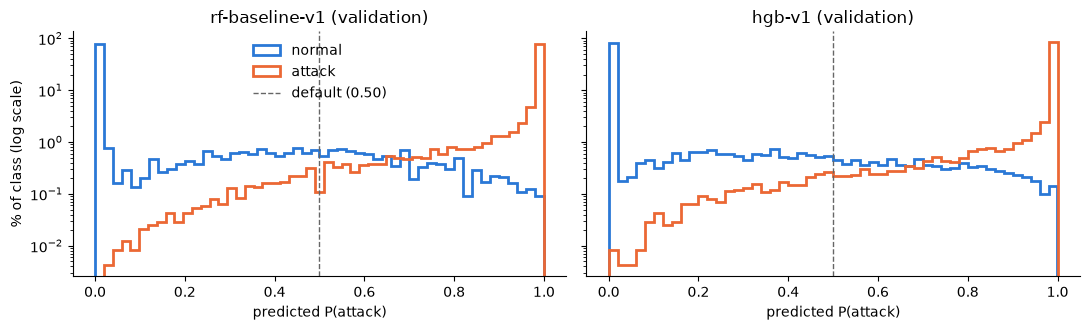

In [2]:
COLORS = {0: "#2a78d6", 1: "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (name, proba) in zip(axes, val_proba.items()):
    for label, label_name in [(0, "normal"), (1, "attack")]:
        scores = proba[y_val == label]
        weights = np.full(len(scores), 100.0 / len(scores))
        ax.hist(
            scores,
            bins=50,
            histtype="step",
            linewidth=2,
            color=COLORS[label],
            label=label_name,
            weights=weights,
        )
    ax.axvline(0.50, color="#666", linestyle="--", linewidth=1, label="default (0.50)")
    ax.set(
        yscale="log",
        xlabel="predicted P(attack)",
        title=f"{name} (validation)",
    )
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("% of class (log scale)")
axes[0].legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

## 3. Sweep thresholds from 0.01 to 0.99
For every candidate threshold, we compute **recall** (fraction of attacks caught) and **FPR** (fraction of normal flows falsely flagged). Then we pick the threshold that minimizes FPR while keeping recall ≥ 95%.

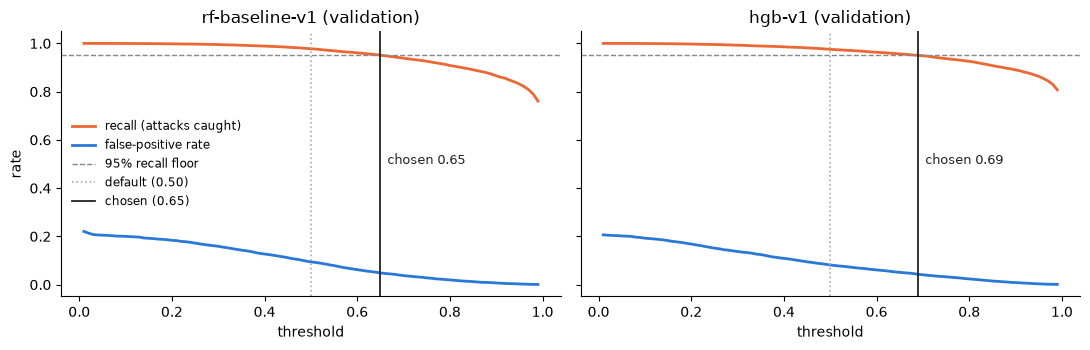

In [3]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)
MIN_RECALL = 0.95


def sweep_thresholds(y_true, proba):
    y_true = np.asarray(y_true)
    rows = []
    for t in THRESHOLDS:
        pred = proba >= t
        tp = int((pred & (y_true == 1)).sum())
        fn = int((~pred & (y_true == 1)).sum())
        fp = int((pred & (y_true == 0)).sum())
        tn = int((~pred & (y_true == 0)).sum())
        rows.append(
            {
                "threshold": t,
                "recall": tp / (tp + fn),
                "fpr": fp / (fp + tn),
                "precision": tp / (tp + fp) if (tp + fp) else 1.0,
                "false_alarms": fp,
                "missed_attacks": fn,
            }
        )
    return pd.DataFrame(rows)


val_curves = {name: sweep_thresholds(y_val, proba) for name, proba in val_proba.items()}

chosen = {}
for name, curve in val_curves.items():
    valid = curve[curve["recall"] >= MIN_RECALL]
    chosen[name] = valid.loc[valid["fpr"].idxmin()]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, curve) in zip(axes, val_curves.items()):
    t_star = chosen[name]["threshold"]
    ax.plot(curve["threshold"], curve["recall"], color="#eb6834", linewidth=2, label="recall (attacks caught)")
    ax.plot(curve["threshold"], curve["fpr"], color="#2a78d6", linewidth=2, label="false-positive rate")
    ax.axhline(MIN_RECALL, color="#888", linestyle="--", linewidth=1, label="95% recall floor")
    ax.axvline(0.50, color="#aaa", linestyle=":", linewidth=1.2, label="default (0.50)")
    ax.axvline(t_star, color="#222", linewidth=1.3, label=f"chosen ({t_star:.2f})")
    ax.text(t_star + 0.015, 0.50, f"chosen {t_star:.2f}", fontsize=9, color="#222")
    ax.set(title=f"{name} (validation)", xlabel="threshold")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("rate")
axes[0].legend(frameon=False, loc="center left", fontsize=8.5)
plt.tight_layout()
plt.show()

## 4. Default (0.50) vs. chosen threshold
Comparing the default `0.50` cutoff against our chosen threshold shows both the rate change and the actual number of alerts/misses on the validation set.

In [4]:
summary_rows = []
for name, curve in val_curves.items():
    default_row = curve.set_index("threshold").loc[0.50]
    chosen_row = chosen[name]
    for setting, t, row in [
        ("default (0.50)", 0.50, default_row),
        (f"chosen ({chosen_row['threshold']:.2f})", chosen_row["threshold"], chosen_row),
    ]:
        summary_rows.append(
            {
                "model": name,
                "setting": setting,
                "threshold": t,
                "recall": row["recall"],
                "fpr": row["fpr"],
                "precision": row["precision"],
                "false_alarms": int(row["false_alarms"]),
                "missed_attacks": int(row["missed_attacks"]),
            }
        )

pd.DataFrame(summary_rows).round(4)

,model,setting,threshold,recall,fpr,precision,false_alarms,missed_attacks
0,rf-baseline-v1,default (0.50),0.50,0.9775,0.0944,0.9567,1057,537
1,rf-baseline-v1,chosen (0.65),0.65,0.9514,0.0485,0.9766,543,1160
2,hgb-v1,default (0.50),0.50,0.9754,0.0816,0.9622,914,586
3,hgb-v1,chosen (0.69),0.69,0.9504,0.0429,0.9793,480,1184


## Key takeaways
- **Raising the threshold cuts validation false alarms roughly in half** while keeping recall ≥ 95%:
  - **`hgb-v1`:** threshold `0.50 → 0.69` drops FPR from **8.2% → 4.3%** (914 → 480 false alarms), while recall moves from `97.5% → 95.0%`.
  - **`rf-baseline-v1`:** threshold `0.50 → 0.65` drops FPR from **9.4% → 4.9%** (1,057 → 543 false alarms), while recall moves from `97.8% → 95.1%`.
- **`hgb-v1` stays ahead of `rf-baseline-v1`** at both the default and tuned thresholds (lower FPR and higher precision).
- **Keep in mind:** these are validation numbers from the training file. Because of distribution shift to the official test file (seen in notebook 02), test FPR will be higher than validation FPR—which we will check **once** at the end.